<a href="https://colab.research.google.com/github/KCGSPerera/CM2604-Telco-Customer-Churn/blob/main/CM2604_Telco_Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CM2604 Machine Learning Coursework — Part 1

Student name:
Student ID:

Objective:
Predict customer churn using KNN, Logistic Regression,
and Random Forest, and compare their performance.

Dataset: Telco Customer Churn
Dataset source: To be recorded when downloaded

Reproducibility:
Use a fixed random seed of 42 for applicable experiments.

AI assistance:
ChatGPT is being used to support planning, implementation,
explanation, and report preparation. Exact prompts, dates,
uses, and verification will be recorded in a separate AI-use log.



In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Setup successful")

Python: 3.13.18
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1
Setup successful


## Dataset provenance

Dataset: Telco Customer Churn
Source: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
Downloaded on: [enter your actual download date]
Original filename: WA_Fn-UseC_-Telco-Customer-Churn.csv

Target: Churn
Yes = customer left the service
No = customer remained with the service

The original CSV is preserved without modification.

3. Upload and load the CSV

In [2]:
from google.colab import files
import io
import hashlib

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
filename = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

raw_bytes = uploaded[filename]
df_raw = pd.read_csv(io.BytesIO(raw_bytes))

# Work on a copy while preserving the original data.
df = df_raw.copy()

print("Dataset shape:", df.shape)
print("File SHA-256:", hashlib.sha256(raw_bytes).hexdigest())

display(df.head())

Dataset shape: (7043, 21)
File SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


4. Check its structure

In [5]:
print("COLUMN TYPES")
df.info()

print("\nTARGET COUNTS")
print(df["Churn"].value_counts(dropna=False))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nDUPLICATE CUSTOMER IDs")
print(df["customerID"].duplicated().sum())

print("\nMISSING VALUES DETECTED BY PANDAS")
print(df.isna().sum())

COLUMN TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-nu

5. Check blank strings and invalid charges

## Data quality checks

Check for blank text values and investigate why TotalCharges
is stored as text. Preserve the original dataset and record
any changes before modelling.

In [6]:
# Find empty strings or strings containing only whitespace.
text_columns = df.select_dtypes(include=["object", "string"]).columns

blank_counts = df[text_columns].apply(
    lambda column: column.str.strip().eq("").sum()
)

print("BLANK STRING COUNTS")
print(blank_counts[blank_counts > 0])

# Attempt conversion without changing the dataframe yet.
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

invalid_charge_mask = total_charges_numeric.isna()

print("\nTOTAL CHARGES VALUES THAT CANNOT BE PARSED")
print("Count:", invalid_charge_mask.sum())

display(
    df.loc[
        invalid_charge_mask,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

print("\nRAW VALUES — repr() makes whitespace visible")
print(
    df.loc[invalid_charge_mask, "TotalCharges"]
      .map(repr)
      .value_counts()
)

BLANK STRING COUNTS
TotalCharges    11
dtype: int64

TOTAL CHARGES VALUES THAT CANNOT BE PARSED
Count: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



RAW VALUES — repr() makes whitespace visible
TotalCharges
' '    11
Name: count, dtype: int64


6. Convert the column and reserve the test set

In [7]:
from sklearn.model_selection import train_test_split

# Deterministic type conversion; no statistics are learned here.
df["TotalCharges"] = total_charges_numeric

# Confirm the target contains only the expected labels.
assert set(df["Churn"].unique()) == {"Yes", "No"}

# Exclude the identifier and target from model inputs.
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining churn percentages")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest churn percentages")
print(y_test.value_counts(normalize=True).mul(100).round(2))

# Keep a training-only dataframe for exploratory analysis.
train_eda = X_train.copy()
train_eda["Churn"] = y_train.map({0: "No", 1: "Yes"})

Training set: (5634, 19)
Test set: (1409, 19)

Training churn percentages
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Test churn percentages
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


7. Summarise the training data

## Exploratory data analysis — training data

Exploratory analysis uses only the training partition.
The held-out test partition is reserved for final evaluation.

The initial audit identified 11 blank TotalCharges values,
all associated with zero tenure. These were converted to
missing numeric values, and the affected records were retained.
Imputation will be fitted within the modelling pipelines.

In [9]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

print("TRAINING DATA — NUMERIC SUMMARY")
display(train_eda[numeric_features].describe().round(2))

print("\nTRAINING DATA — MISSING VALUES")
print(train_eda.isna().sum().loc[lambda counts: counts > 0])

print("\nTRAINING DATA — CATEGORICAL VALUES")
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

for column in categorical_features:
    print(f"\n{column}:")
    print(train_eda[column].value_counts(dropna=False))

TRAINING DATA — NUMERIC SUMMARY


,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5626.00
mean,32.49,64.93,2302.60
std,24.57,30.14,2279.17
min,0.00,18.40,18.85
25%,9.00,35.66,407.28
50%,29.00,70.50,1398.12
75%,55.00,90.00,3838.61
max,72.00,118.75,8684.80



TRAINING DATA — MISSING VALUES
TotalCharges    8
dtype: int64

TRAINING DATA — CATEGORICAL VALUES

gender:
gender
Male      2833
Female    2801
Name: count, dtype: int64

SeniorCitizen:
SeniorCitizen
0    4714
1     920
Name: count, dtype: int64

Partner:
Partner
No     2905
Yes    2729
Name: count, dtype: int64

Dependents:
Dependents
No     3955
Yes    1679
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    5075
No      559
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  2685
Yes                 2390
No phone service     559
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    2483
DSL            1937
No             1214
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     2797
Yes                    1623
No internet service    1214
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     2442
Yes                    1978
No internet service    1214
Name: count, dtype: int64

D

8. Create the first EDA charts

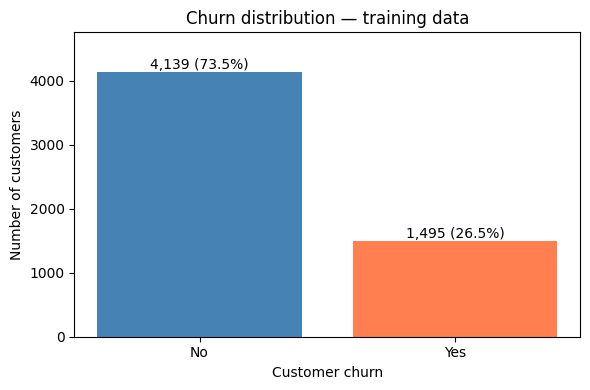

In [10]:
# Chart 1: training target distribution
counts = train_eda["Churn"].value_counts().reindex(["No", "Yes"])

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=["steelblue", "coral"])

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{count:,} ({count / counts.sum():.1%})",
        ha="center",
        va="bottom"
    )

ax.set(
    title="Churn distribution — training data",
    xlabel="Customer churn",
    ylabel="Number of customers"
)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

9. compare numeric features between churners and non-churners

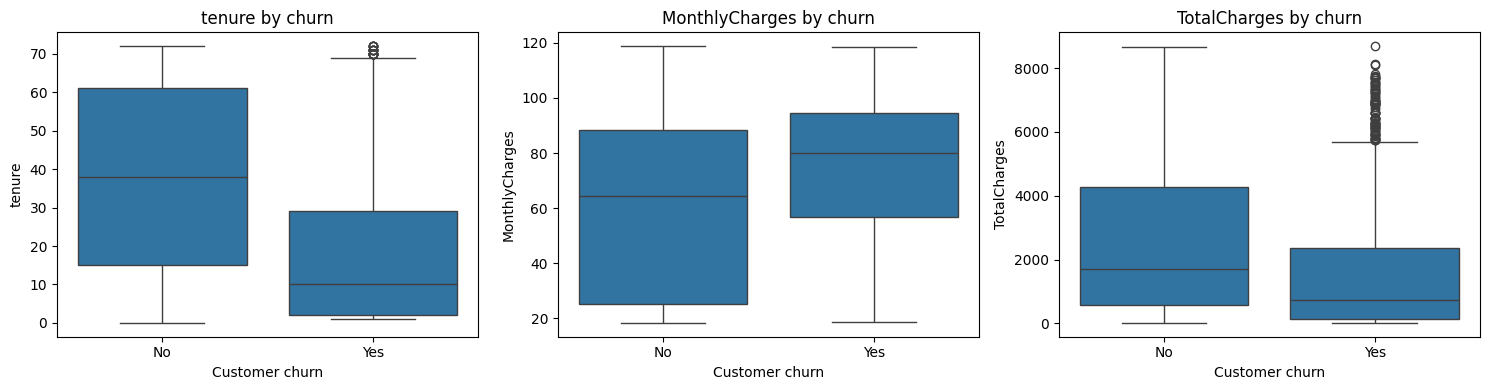

MEDIANS BY CHURN — TRAINING DATA


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.40,1691.9
Yes,10.0,79.95,740.3


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numeric_features):
    sns.boxplot(
        data=train_eda,
        x="Churn",
        y=column,
        order=["No", "Yes"],
        ax=ax
    )
    ax.set_title(f"{column} by churn")
    ax.set_xlabel("Customer churn")

plt.tight_layout()
plt.show()

print("MEDIANS BY CHURN — TRAINING DATA")
display(
    train_eda.groupby("Churn")[numeric_features]
             .median()
             .reindex(["No", "Yes"])
             .round(2)
)